# 01 · Corpus & Chunking — Turning Notes into Searchable Passages
**Project 2 of 5 — RAG Notes Assistant.** A *Retrieval-Augmented Generation* (RAG) chatbot answers questions **from your own documents** instead of from what a language model remembers. This notebook covers step 1: load the notes and split them into good passages ("chunks").

| Notebook | Topic |
|---|---|
| **01 (this)** | Corpus, chunking, chunk-size trade-offs |
| 02 | Retrieval experiments (BM25, character n-grams, LSA, fusion) and the evaluation set |
| 03 | Answer generation, citations, and refusing out-of-scope questions |

**Corpus:** my own study notes — NumPy, Pandas, Matplotlib, Seaborn and Scikit-learn notebooks (exported to Markdown), a pandas interview Q&A set, and the public *100 NumPy exercises* list (Rougier, MIT licence; questions only).

In [1]:
import sys, warnings, collections, statistics as st; warnings.filterwarnings('ignore'); sys.path.insert(0, '.')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from rag_notes.loader import load_documents
from rag_notes.chunker import build_chunks, chunk_document, _blocks
sns.set_theme(style='whitegrid')
docs = load_documents('data/notes'); print(len(docs), 'documents')

28 documents


## 1. What is in the corpus?

In [ ]:
rows=[dict(file=d.path, series=d.series, kind=d.kind, chars=len(d.text), words=len(d.text.split()), code_blocks=d.text.count('```')//2) for d in docs]
corpus=pd.DataFrame(rows); corpus.head(10)

,file,series,kind,chars,words,code_blocks
0,exercises/100_numpy_exercises.md,exercises,exercises,9967,1783,6
1,interview-qa/04_pandas_interview_qna.md,interview-qa,qa,11459,1637,51
2,matplotlib/01_matplotlib_basics.md,matplotlib,notes,7587,812,24
3,matplotlib/02_plot_types.md,matplotlib,notes,7535,823,23
4,matplotlib/03_subplots_styling.md,matplotlib,notes,4705,487,13
5,matplotlib/04_advanced.md,matplotlib,notes,5360,657,15
6,matplotlib/05_real_world_weather_eda.md,matplotlib,notes,11975,1236,36
7,numpy/01_numpy_basics.md,numpy,notes,18211,2576,77
8,numpy/02_array_creation.md,numpy,notes,16524,2273,80
9,numpy/03_indexing_slicing.md,numpy,notes,14787,2189,64


In [2]:
corpus.groupby('series').agg(files=('file','count'), words=('words','sum'), code_blocks=('code_blocks','sum')).sort_values('words',ascending=False)

NameError: name 'corpus' is not defined

In [ ]:
print('Total words: {:,} | total characters: {:,}'.format(corpus.words.sum(), corpus.chars.sum()))

Total words: 32,445 | total characters: 258,146


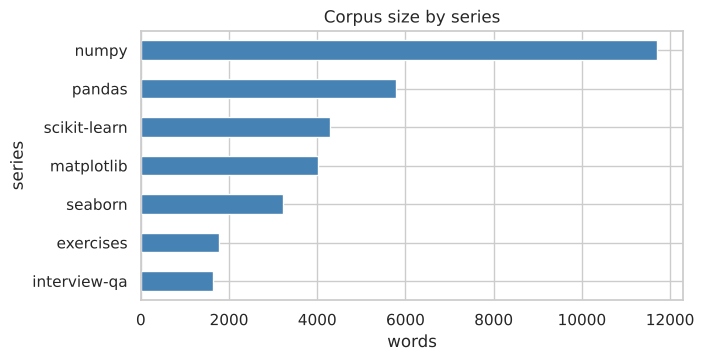

In [ ]:
corpus.groupby('series').words.sum().sort_values().plot(kind='barh', color='steelblue', figsize=(7,3.5)); plt.xlabel('words'); plt.title('Corpus size by series'); plt.show()

In [ ]:
corpus.groupby('kind').agg(files=('file','count'), words=('words','sum'))

,files,words
kind,,
exercises,1,1783
notes,25,29025
qa,1,1637


Three **kinds** of material: ordinary *notes*, a *qa* file (pandas interview questions with answers) and an *exercises* list (questions only). We keep `kind` as metadata because exercises behave very differently in search (see notebook 02).

## 2. A first look at the raw text

In [ ]:
print(docs[8].path); print(docs[8].text[:900])

numpy/02_array_creation.md
# 02 — Array Creation in NumPy (Preetham's NumPy Mastery Series)

Part 2 of 5. This notebook covers **every method** to create NumPy arrays: from Python objects, using built-in generator functions, and using the random module.

## 1. Creating Arrays from Python Objects

```python
import numpy as np

# From a list
fruits_count = np.array([12, 5, 8, 20])
print('From list:', fruits_count)

# From a tuple
coordinates = np.array((10.5, 20.3, 30.7))
print('From tuple:', coordinates)

# From a list of lists (2D)
seating_chart = np.array([[1, 2, 3], [4, 5, 6]])
print('From nested list:\n', seating_chart)
```

Output:
```text
From list: [12  5  8 20]
From tuple: [10.5 20.3 30.7]
From nested list:
 [[1 2 3]
 [4 5 6]]
```

```python
# From a set (order not guaranteed, generally avoided but possible via list conversion)
unique_ids = {101, 102, 103, 104}
ids_array = np.array(list(unique_ids))
print('


In [ ]:
print(next(d for d in docs if d.kind=='exercises').text[:700])




# 100 numpy exercises

This is a collection of exercises that have been collected in the numpy mailing list, on stack overflow
and in the numpy documentation. The goal of this collection is to offer a quick reference for both old
and new users but also to provide a set of exercises for those who teach.


If you find an error or think you've a better way to solve some of them, feel
free to open an issue at <https://github.com/rougier/numpy-100>.
File automatically generated. See the documentation to update questions/answers/hints programmatically.

#### 1. Import the numpy package under the name `np` (★☆☆)

#### 2. Print the numpy version and the configuration (★☆☆)

#### 3. Create a null 


## 3. Why chunking matters

A language model can only read a few thousand words at once, and a search engine works best when each result is **about one thing**. So we split documents into passages:

| Too big | Too small |
|---|---|
| matches many topics, dilutes keywords, wastes the LLM's context | loses context (a code line without its explanation) |

Our strategy: split on **Markdown headings** (each heading = one concept), keep **code blocks intact**, merge tiny neighbours, split oversized sections at paragraph boundaries.

### 3.1 Trap: `#` inside code is a comment, not a heading

In [ ]:
sample = '''## 1. Example\n\n```python\n# this is a comment\nx = 1\n```\n\n## 2. Next\n\ntext'''
list(_blocks(sample))

[('heading', 2, '1. Example'),
 ('code', '```python\n# this is a comment\nx = 1\n```'),
 ('heading', 2, '2. Next'),
 ('para', 'text')]

In [ ]:
naive = [l for l in sample.splitlines() if l.startswith('#')]; print('naive heading finder sees :', naive)
print('fence-aware finder sees:', [b[2] for b in _blocks(sample) if b[0]=='heading'])

naive heading finder sees : ['## 1. Example', '# this is a comment', '## 2. Next']
fence-aware finder sees: ['1. Example', '2. Next']


A naive `startswith('#')` splitter would cut every code comment into a fake section. Our block parser tracks fences.

## 4. Build the chunks

In [ ]:
chunks = build_chunks(docs, max_chars=1200, min_chars=200, drop_nav=False)
print(len(chunks), 'chunks')

624 chunks


In [ ]:
cdf = pd.DataFrame([dict(id=c.id, source=c.source, series=c.series, kind=c.kind, chars=c.n_chars, has_code=c.has_code, section=c.section) for c in chunks]); cdf.head()

,id,source,series,kind,chars,has_code,section
0,0,exercises/100_numpy_exercises.md,exercises,exercises,551,False,100 numpy exercises
1,1,exercises/100_numpy_exercises.md,exercises,exercises,58,False,100 numpy exercises > 1. Import the numpy pack...
2,2,exercises/100_numpy_exercises.md,exercises,exercises,59,False,100 numpy exercises > 2. Print the numpy versi...
3,3,exercises/100_numpy_exercises.md,exercises,exercises,45,False,100 numpy exercises > 3. Create a null vector ...
4,4,exercises/100_numpy_exercises.md,exercises,exercises,54,False,100 numpy exercises > 4. How to find the memor...


In [ ]:
cdf.chars.describe().round(0)

count     624.0
mean      412.0
std       256.0
min        36.0
25%       244.0
50%       360.0
75%       537.0
max      1198.0
Name: chars, dtype: float64

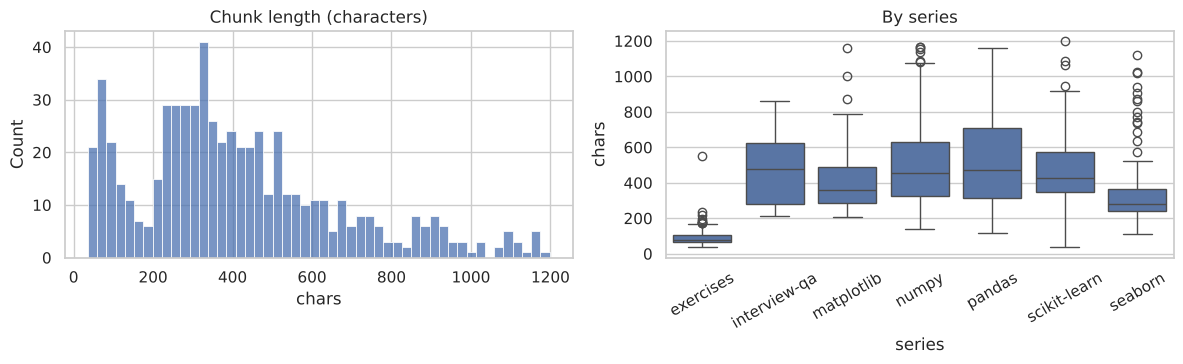

In [ ]:
fig,ax=plt.subplots(1,2,figsize=(12,3.8)); sns.histplot(cdf.chars,bins=50,ax=ax[0]); ax[0].set_title('Chunk length (characters)')
sns.boxplot(data=cdf,x='series',y='chars',ax=ax[1]); ax[1].tick_params(axis='x',rotation=30); ax[1].set_title('By series'); plt.tight_layout(); plt.show()

In [ ]:
cdf.groupby('kind').chars.describe().round(0)

,count,mean,std,min,25%,50%,75%,max
kind,,,,,,,,
exercises,101.0,97.0,61.0,36.0,64.0,79.0,108.0,551.0
notes,499.0,473.0,236.0,39.0,303.0,410.0,586.0,1198.0
qa,24.0,477.0,201.0,211.0,278.0,479.0,625.0,863.0


In [ ]:
print('chunks containing code: %.1f%%' % (cdf.has_code.mean()*100))

chunks containing code: 76.3%


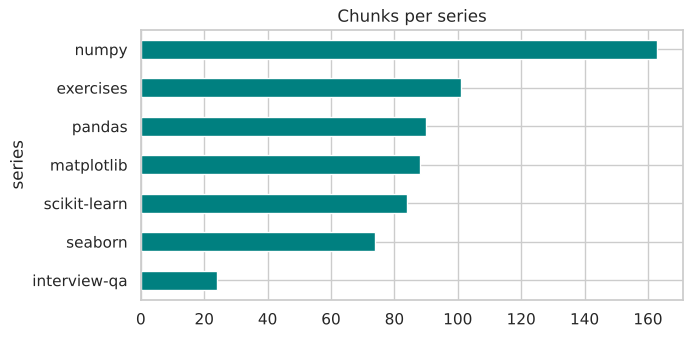

In [ ]:
cdf.groupby('series').size().sort_values().plot(kind='barh',color='teal',figsize=(7,3.5)); plt.title('Chunks per series'); plt.show()

### 4.1 Look at some chunks

In [ ]:
for c in [chunks[210], chunks[330]]:
    print('SOURCE :', c.source); print('SECTION:', c.section); print('CHARS  :', c.n_chars); print(c.text[:500]); print('-'*80)

SOURCE : matplotlib/05_real_world_weather_eda.md
SECTION: 05 — Real-World Weather Data EDA (Your Original Project, Completed) > 21. Hourly Temperature Pattern
CHARS  : 332
## 21. Hourly Temperature Pattern

```python
hourly_avg = df.groupby('Hour')['Temperature'].mean()
plt.figure(figsize=(10, 5))
hourly_avg.plot(marker='o', color='crimson', linewidth=2)
plt.title('Average Temperature by Hour of Day')
plt.xlabel('Hour (24h)')
plt.ylabel('Avg Temperature (C)')
plt.grid(True, alpha=0.3)
plt.show()
```
--------------------------------------------------------------------------------
SOURCE : numpy/04_reshaping_stacking.md
SECTION: 04 — Reshaping & Stacking in NumPy (Preetham's NumPy Mastery Series) > 18. `np.roll()` — Circular Shifting of Elements
CHARS  : 370
## 18. `np.roll()` — Circular Shifting of Elements

```python
playlist_queue = np.array(['Song1', 'Song2', 'Song3', 'Song4', 'Song5'])
shifted = np.roll(playlist_queue, 2)
print('Original:', playlist_queue)
print('Rolled by 2:', shif

### 4.2 What gets indexed

In [ ]:
print(chunks[210].index_text[:300])

matplotlib | 05 — Real-World Weather Data EDA (Your Original Project, Completed) > 21. Hourly Temperature Pattern
## 21. Hourly Temperature Pattern

```python
hourly_avg = df.groupby('Hour')['Temperature'].mean()
plt.figure(figsize=(10, 5))
hourly_avg.plot(marker='o', color='crimson', linewidth=2)
p


The text we **index** gets a one-line header (series + file title + section path) prepended. This *contextual header* tells the search engine what a code-only chunk is about.

## 5. Problem chunks

### 5.1 Very short chunks

In [ ]:
short = cdf[cdf.chars<120]; print(len(short), 'chunks under 120 characters'); short.kind.value_counts()

88 chunks under 120 characters


kind
exercises    82
notes         6
Name: count, dtype: int64

In [ ]:
short.sort_values('chars').head(8)[['kind','chars','section']]

,kind,chars,section
82,exercises,36,100 numpy exercises > 82. Compute a matrix ran...
468,notes,39,01 — Scikit-learn Basics (Preetham's Scikit-le...
11,exercises,43,100 numpy exercises > 11. Create a 3x3 identit...
22,exercises,44,100 numpy exercises > 22. Normalize a 5x5 rand...
3,exercises,45,100 numpy exercises > 3. Create a null vector ...
72,exercises,48,100 numpy exercises > 72. How to swap two rows...
43,exercises,50,100 numpy exercises > 43. Make an array immuta...
4,exercises,54,100 numpy exercises > 4. How to find the memor...


Most very short chunks are the *exercise questions* (a single sentence). Short texts can win keyword search unfairly (BM25 favours short documents) — a real effect we will measure in notebook 02.

### 5.2 Navigation chunks (“Summary — What You Learned”, “Next Notebook”)

In [ ]:
nav = cdf[cdf.section.str.contains(r'(?:^|> )(?:\d+[a-z]?\.\s*)?(?:summary\b|next notebook)|series complete|what you learned', case=False, regex=True)]
print(len(nav),'navigation chunks'); nav[['source','chars']].head()

42 navigation chunks


,source,chars
124,interview-qa/04_pandas_interview_qna.md,280
146,matplotlib/01_matplotlib_basics.md,254
164,matplotlib/02_plot_types.md,228
177,matplotlib/03_subplots_styling.md,226
191,matplotlib/04_advanced.md,269


In [ ]:
print(nav.iloc[0].section); print([c for c in chunks if c.id==nav.iloc[0].id][0].text[:500])

Pandas Interview Q&A — Practice Notebook > Summary


## Summary

This notebook covers 25 classic pandas interview-style questions: selection, filtering, sorting, grouping, pivoting, replacing values, and row-wise operations — all on a single small, self-contained dataset. No external files needed; runs anywhere pandas is installed.


These summary chunks mention *every* topic of a notebook, so they match almost any keyword and push the real answer down. We drop them by default (`drop_nav=True`).

In [ ]:
with_nav, without_nav = len(build_chunks(docs, drop_nav=False)), len(build_chunks(docs, drop_nav=True)); print(with_nav, '→', without_nav, 'chunks after dropping navigation')

624 → 582 chunks after dropping navigation


## 6. Chunk-size trade-off

In [ ]:
rows=[]
for mx in [400,800,1200,2000,4000]:
    for mn in [0,200]:
        ch=build_chunks(docs,max_chars=mx,min_chars=mn); L=[c.n_chars for c in ch]
        rows.append(dict(max_chars=mx,min_chars=mn,n_chunks=len(ch),median_chars=int(np.median(L)),p95_chars=int(np.percentile(L,95))))
pd.DataFrame(rows)

,max_chars,min_chars,n_chunks,median_chars,p95_chars
0,400,0,899,280,449
1,400,200,893,283,450
2,800,0,654,339,733
3,800,200,635,359,741
4,1200,0,602,345,920
5,1200,200,582,364,928
6,2000,0,596,346,920
7,2000,200,576,365,926
8,4000,0,595,346,920
9,4000,200,575,365,926


Smaller `max_chars` ⇒ more, shorter chunks. We will pick the setting by **measuring retrieval quality** in notebook 02, not by guessing.

## 7. Chunk coverage checks (nothing lost?)

In [ ]:
src_words=sum(len(d.text.split()) for d in docs); ch=build_chunks(docs,drop_nav=False); ch_words=sum(len(c.text.split()) for c in ch)
print(f'source words {src_words:,} | chunk words {ch_words:,} | kept {ch_words/src_words:.1%}')

source words 32,445 | chunk words 32,401 | kept 99.9%


In [ ]:
lost=src_words-ch_words; print('words not in any chunk (bare headings of merged/empty sections):', lost)

words not in any chunk (bare headings of merged/empty sections): 44


In [ ]:
per_file=pd.DataFrame([dict(file=d.path, kept=sum(len(c.text.split()) for c in ch if c.source==d.path)/max(len(d.text.split()),1)) for d in docs]).sort_values('kept'); per_file.head(5)

,file,kept
4,matplotlib/03_subplots_styling.md,0.977413
5,matplotlib/04_advanced.md,0.978691
2,matplotlib/01_matplotlib_basics.md,0.986453
3,matplotlib/02_plot_types.md,0.990279
0,exercises/100_numpy_exercises.md,1.000000


In [ ]:
print('exercises in corpus vs exercise chunks:', sum(1 for l in docs[[d.kind for d in docs].index('exercises')].text.splitlines() if l.startswith('#### ')), '→', sum(1 for c in ch if c.kind=='exercises')-1)

exercises in corpus vs exercise chunks: 100 → 100


## 8. Why not just use fixed-size windows?

In [ ]:
def fixed_windows(text, size=800): return [text[i:i+size] for i in range(0,len(text),size)]
broken=0; total=0
for d in docs[:10]:
    for w in fixed_windows(d.text):
        total+=1; broken += w.count('```')%2==1
print(f'{broken} of {total} fixed 800-char windows cut a code block in half ({broken/total:.0%})')

50 of 139 fixed 800-char windows cut a code block in half (36%)


In [ ]:
ch_all=build_chunks(docs,drop_nav=False); bad=sum(c.text.count('```')%2==1 for c in ch_all); print(f'heading-aware chunks with an unbalanced code fence: {bad} of {len(ch_all)}')

heading-aware chunks with an unbalanced code fence: 0 of 624


Fixed windows cut code blocks in half roughly a third of the time in this corpus; heading-aware chunks never do (code fences are atomic unless a single block is huge).

In [ ]:
big=[c for c in chunks if c.n_chars>1200]; print('chunks over max_chars:', len(big), '(single code blocks larger than the limit are kept whole)')

chunks over max_chars: 0 (single code blocks larger than the limit are kept whole)


## 9. Summary
| Decision | Why |
|---|---|
| Split on headings, fence-aware | one concept per chunk, code never cut |
| Prepend `series \| file > section` header to the *indexed* text | gives code-only chunks context |
| Drop “Summary / Next notebook” chunks | they match everything |
| Treat exercises specially (`kind='exercises'`) | each question is its own tiny chunk |
| Pick sizes by measurement | notebook 02 |

**Next:** [02 – Retrieval experiments](02_retrieval_experiments.ipynb)